# IMDB Movie Review Sentiment Analysis
Dataset: [Kaggle — IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews)



In [32]:
import os, re, html, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")
RANDOM_STATE=42
MODEL_PATH="imdb_sentiment_model.pkl"

## 1. Data Loading


In [19]:
df=pd.read_csv("IMDB Dataset.csv")

In [20]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [21]:
print(df.dtypes)

review       object
sentiment    object
dtype: object


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [23]:
display(df.describe(include="all").T)

,count,unique,top,freq
review,50000,49582,Loved today's show!!! It was a variety and not...,5
sentiment,50000,2,positive,25000


## 2. Data Inspection & EDA


In [24]:
required={"review","sentiment"}
if not required.issubset(df.columns): raise ValueError(f"Expected columns {required}; got {df.columns.tolist()}")
df["review"]=df["review"].astype("string")
df["sentiment"]=df["sentiment"].astype("string")
print("Missing values:"); display(df.isna().sum().to_frame("missing"))
print("Exact duplicate rows:",int(df.duplicated().sum()))
print("Blank reviews:",int(df["review"].fillna("").str.strip().eq("").sum()))
print("Raw labels:",df["sentiment"].str.lower().value_counts(dropna=False))

Missing values:


,missing
review,0
sentiment,0


Exact duplicate rows: 418
Blank reviews: 0
Raw labels: sentiment
positive    25000
negative    25000
Name: count, dtype: Int64


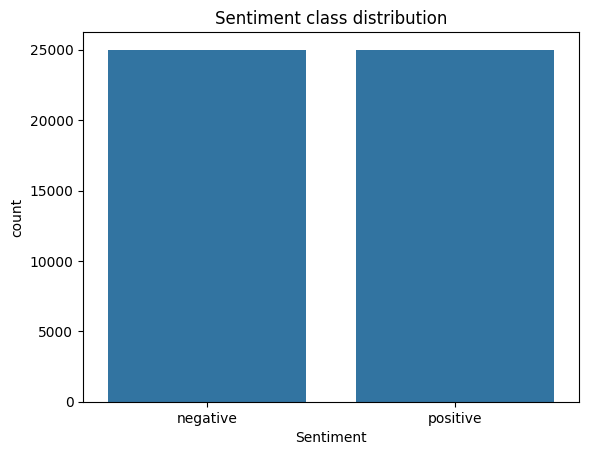

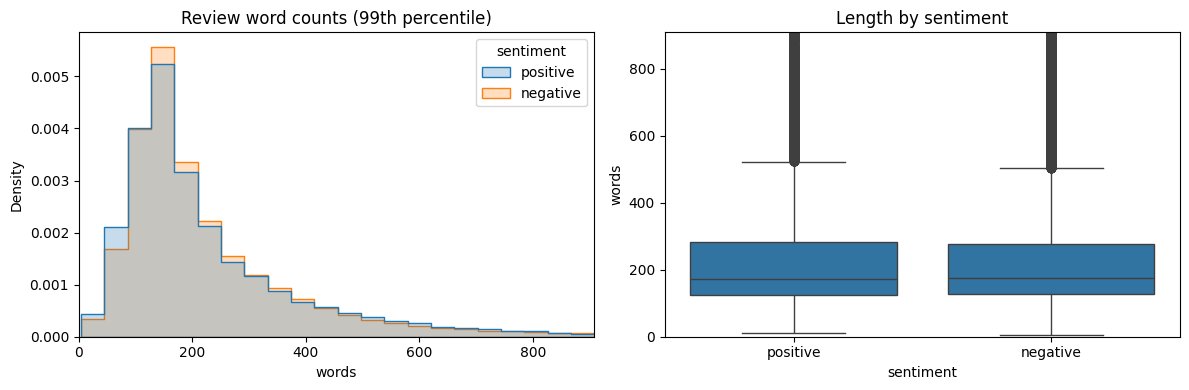

In [25]:

sns.countplot(x=df["sentiment"].str.lower(),order=["negative","positive"])
plt.title("Sentiment class distribution"); plt.xlabel("Sentiment"); plt.show()
eda=df.copy()
eda["words"]=eda["review"].fillna("").str.split().str.len()
eda["chars"]=eda["review"].fillna("").str.len()
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=eda,x="words",hue=eda["sentiment"].str.lower(),bins=60,element="step",stat="density",common_norm=False,ax=ax[0])
ax[0].set_xlim(0,eda["words"].quantile(.99)); ax[0].set_title("Review word counts (99th percentile)")
sns.boxplot(data=eda,x=eda["sentiment"].str.lower(),y="words",ax=ax[1])
ax[1].set_ylim(0,eda["words"].quantile(.99)); ax[1].set_title("Length by sentiment")
plt.tight_layout(); plt.show()


In [26]:
display(eda["words"].quantile([0,.25,.5,.75,.95,.99,1]).to_frame("word_count"))

,word_count
0.00,4.0
0.25,126.0
0.50,173.0
0.75,280.0
0.95,590.0
0.99,908.0
1.00,2470.0


### EDA interpretation


## 3. Cleaning & 4. Feature Engineering


In [27]:
def clean_text(text):
    if pd.isna(text): return ""
    text=html.unescape(str(text))
    text=re.sub(r"<br\s*/?>"," ",text,flags=re.IGNORECASE)
    text=re.sub(r"<[^>]+>"," ",text)
    return re.sub(r"\s+"," ",text).strip()
n_before=len(df)
df["sentiment"]=df["sentiment"].str.strip().str.lower()
df["review"]=df["review"].fillna("").map(clean_text)
df=df[df["review"].str.strip().ne("") & df["sentiment"].notna()].copy()
df=df[df["sentiment"].isin(["positive","negative"])].drop_duplicates(subset=["review","sentiment"]).reset_index(drop=True)
print("Rows before:",n_before,"after:",len(df),"removed:",n_before-len(df))
display(df.isna().sum().to_frame("missing after cleaning"))
display(df["sentiment"].value_counts().to_frame("count"))
if df["sentiment"].nunique()!=2: raise ValueError("Both positive and negative labels are required.")

Rows before: 50000 after: 49578 removed: 422


,missing after cleaning
review,0
sentiment,0


,count
sentiment,
positive,24882
negative,24696


## 5. Vectorization & Scaling


In [28]:
X=df["review"].astype(str); y=df["sentiment"].astype(str)
X_train,X_temp,y_train,y_temp=train_test_split(X,y,test_size=.30,random_state=42,stratify=y)
X_valid,X_test,y_valid,y_test=train_test_split(X_temp,y_temp,test_size=.50,random_state=42,stratify=y_temp)
print(f"Train {len(X_train):,} ({len(X_train)/len(df):.1%}); validation {len(X_valid):,}; test {len(X_test):,}")

Train 34,704 (70.0%); validation 7,437; test 7,437


## 6. Model Training & 7. Validation


In [29]:
def make_pipeline(clf):
    return Pipeline([("tfidf",TfidfVectorizer(lowercase=True,strip_accents="unicode",ngram_range=(1,2),min_df=2,max_df=.98,max_features=100_000,sublinear_tf=True,dtype=np.float32)),("classifier",clf)])
models={
 "Multinomial Naive Bayes":make_pipeline(MultinomialNB(alpha=.5)),
 "Logistic Regression":make_pipeline(LogisticRegression(C=4,max_iter=1000,solver="liblinear",random_state=42)),
 "Linear SVM":make_pipeline(LinearSVC(C=1,random_state=42))}
def metrics(y_true,pred):
    return {"accuracy":accuracy_score(y_true,pred),"precision_macro":precision_score(y_true,pred,average="macro",zero_division=0),"recall_macro":recall_score(y_true,pred,average="macro",zero_division=0),"f1_macro":f1_score(y_true,pred,average="macro",zero_division=0)}
rows=[]
for name,model in models.items():
    print("Training",name)
    model.fit(X_train,y_train)
    rows.append({"model":name,**metrics(y_valid,model.predict(X_valid))})
results=pd.DataFrame(rows).sort_values(["f1_macro","accuracy"],ascending=False).reset_index(drop=True)
display(results.style.format({c:"{:.4f}" for c in ["accuracy","precision_macro","recall_macro","f1_macro"]}))
best_name=results.iloc[0]["model"]; best_model=models[best_name]
print("Selected by validation macro-F1:",best_name)

Training Multinomial Naive Bayes
Training Logistic Regression
Training Linear SVM


,model,accuracy,precision_macro,recall_macro,f1_macro
0,Linear SVM,0.9111,0.9114,0.9111,0.9111
1,Logistic Regression,0.9109,0.9113,0.9108,0.9108
2,Multinomial Naive Bayes,0.8861,0.8863,0.8861,0.8861


Selected by validation macro-F1: Linear SVM


## 8. Final Test & Experiment Comparison


,accuracy,precision_macro,recall_macro,f1_macro
Linear SVM,0.9148,0.9149,0.9147,0.9147


              precision    recall  f1-score   support

    negative     0.9213    0.9063    0.9137      3705
    positive     0.9085    0.9231    0.9157      3732

    accuracy                         0.9148      7437
   macro avg     0.9149    0.9147    0.9147      7437
weighted avg     0.9149    0.9148    0.9147      7437



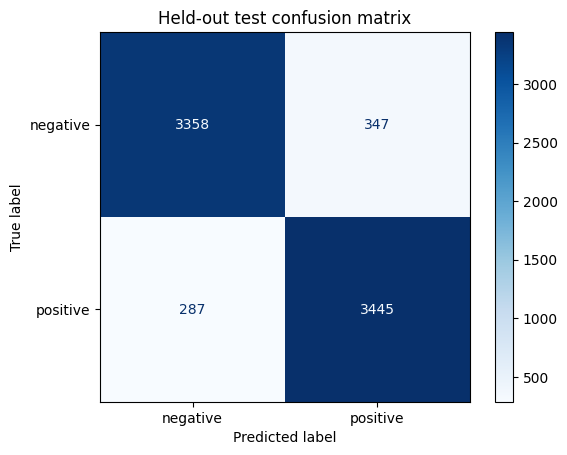

In [30]:
test_pred=best_model.predict(X_test)
test_metrics=metrics(y_test,test_pred)
display(pd.DataFrame([test_metrics],index=[best_name]).style.format("{:.4f}"))
print(classification_report(y_test,test_pred,digits=4,zero_division=0))
cm=confusion_matrix(y_test,test_pred,labels=["negative","positive"])
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["negative","positive"]).plot(values_format="d",cmap="Blues")
plt.title("Held-out test confusion matrix"); plt.show()

## 9. Save Model & 10. Working CLI Prototype


In [33]:
joblib.dump(best_model,MODEL_PATH)
print("Saved:",os.path.abspath(MODEL_PATH))
print(f"Size: {os.path.getsize(MODEL_PATH)/(1024*1024):.2f} MB")
for review in ["A wonderful film with excellent acting.","Boring, badly written, a waste of time.","It had good moments but was not very good."]:
    print(review,"=>",best_model.predict([clean_text(review)])[0])

Saved: /content/imdb_sentiment_model.pkl
Size: 4.15 MB
A wonderful film with excellent acting. => positive
Boring, badly written, a waste of time. => negative
It had good moments but was not very good. => negative


## 11. Download the model


In [34]:
model_file=Path(MODEL_PATH).resolve()
print("Model file:",model_file)
try:
    from google.colab import files
    files.download(str(model_file))
except ImportError:
    print("Local Jupyter: download this file from the file browser or copy it beside cli.py.")

Model file: /content/imdb_sentiment_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>